# Tópico 5 - DummyClassifier e GaussianNB no Pipeline

Este notebook continua a etapa de modelagem da Sprint 3, seguindo o mesmo fluxo do projeto:
- carga do dataset processado (`data/processed/dados_modelo.csv`)
- split temporal em treino (2015-2022) e teste (2023-2024)
- criação de um `Pipeline` com `ColumnTransformer` + classificador
- comparação entre `DummyClassifier` e `GaussianNB`

A ideia é manter a mesma estrutura de dados e o mesmo critério de avaliação aplicado ao longo do projeto, evitando qualquer vazamento da janela futura para o treino.

In [11]:
%pip install -r ../requirements.txt

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\josea\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
)

sns.set_theme(style='whitegrid')


## 1. Carregando o dataset processado

O dataset já foi construído com as features agroclimáticas e a variável alvo `quebra_safra` no notebook de feature engineering.

In [13]:
df = pd.read_csv('../data/processed/dados_modelo.csv')
df = df.sort_values('ano').reset_index(drop=True)
display(df.head())
print(f'Total de registros: {len(df)}')
print(f"Período: {df['ano'].min()} a {df['ano'].max()}")

,ano,PRECTOTCORR,T2M,T2M_MAX,T2M_MIN,RH2M,GWETROOT,quebra_safra,amplitude_termica,precipitacao_por_temperatura,GWET_x_PREC
0,2015,645.49,27.850904,41.79,17.31,61.046274,0.635616,1,24.48,23.175794,410.284055
1,2016,1147.75,26.832432,39.57,15.78,66.810902,0.658962,1,23.79,42.773135,756.323347
2,2017,1561.12,25.576301,39.86,12.24,74.063096,0.714904,0,27.62,61.035368,1116.051104
3,2018,1903.15,25.089068,39.71,13.42,77.658548,0.755589,0,26.29,75.852722,1437.999284
4,2019,1210.35,26.609890,40.91,15.47,68.237671,0.675699,0,25.44,45.483258,817.831837


Total de registros: 10
Período: 2015 a 2024


## 2. Definindo o split temporal

Definido no contrato da Sprint 3, o treino usa as safras antigas e o teste usa as safras recentes, sem embaralhamento aleatório.

> Observação importante: nesta divisão, o conjunto de teste atual contém apenas observações da classe 0 (`Normal`), então a avaliação da classe 1 (`Quebra`) não tem suporte estatístico suficiente para interpretar recall/precisão como resultado final de negócio.

In [14]:
target = 'quebra_safra'
feature_cols = [
    'PRECTOTCORR',
    'T2M',
    'T2M_MAX',
    'T2M_MIN',
    'RH2M',
    'GWETROOT',
    'amplitude_termica',
    'precipitacao_por_temperatura',
    'GWET_x_PREC'
]

train_mask = df['ano'] < 2023
test_mask = df['ano'] >= 2023

X_train = df.loc[train_mask, feature_cols].copy()
y_train = df.loc[train_mask, target].copy()

X_test = df.loc[test_mask, feature_cols].copy()
y_test = df.loc[test_mask, target].copy()

print(f'Treino: {len(X_train)} amostras')
print(f'Teste: {len(X_test)} amostras')
print(f'Classe alvo no treino: {y_train.value_counts().to_dict()}')
print(f'Classe alvo no teste: {y_test.value_counts().to_dict()}')

if y_test.nunique() < 2:
    print('\nATENÇÃO: o conjunto de teste atual não contém casos da classe 1 (Quebra).')
    print('Isso torna a acurácia perfeita enganosa e invalida a interpretação de recall/precisão para a classe minoritária.')
    print('O resultado serve apenas para validar a lógica do Pipeline e do split temporal, não para concluir desempenho real do modelo.')

Treino: 8 amostras
Teste: 2 amostras
Classe alvo no treino: {0: 5, 1: 3}
Classe alvo no teste: {0: 2}

ATENÇÃO: o conjunto de teste atual não contém casos da classe 1 (Quebra).
Isso torna a acurácia perfeita enganosa e invalida a interpretação de recall/precisão para a classe minoritária.
O resultado serve apenas para validar a lógica do Pipeline e do split temporal, não para concluir desempenho real do modelo.


## 3. Pipeline com pré-processamento e classificadores

encapsular o `StandardScaler` e o modelo no mesmo objeto `Pipeline`, para garantir que o ajuste do scaler tenha lugar somente no conjunto de treino.

In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        ('climatic_scaler', StandardScaler(), feature_cols)
    ],
    remainder='drop'
)

dummy_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DummyClassifier(strategy='most_frequent'))
])

gaussian_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GaussianNB())
])

dummy_pipeline.fit(X_train, y_train)
gaussian_pipeline.fit(X_train, y_train)

print('Pipelines treinados com sucesso!')


Pipelines treinados com sucesso!


## 4. Comparando os baselines

A comparação inclui o baseline de classe majoritária (`DummyClassifier`) e um modelo probabilístico simples (`GaussianNB`).

In [16]:
models = {
    'DummyClassifier': dummy_pipeline,
    'GaussianNB': gaussian_pipeline
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    print(f'\n=== {name} ===')
    print(f'Accuracy:  {accuracy:.4f}')
    print(f'Precision: {precision:.4f}')
    print(f'Recall:    {recall:.4f}')
    print(f'F1-score:  {f1:.4f}')
    print(classification_report(y_test, y_pred, labels=[0, 1], target_names=['Normal', 'Quebra'], zero_division=0))
    print('Matriz de confusão:')
    print(cm)

    if y_test.nunique() < 2:
        print('\nInterpretação crítica: como não há casos positivos no teste, a acurácia de 1.00 não representa desempenho real para a classe Quebra.')
    
    results.append({
        'modelo': name,
        'accuracy': accuracy,
        'precision_weighted': precision,
        'recall_weighted': recall,
        'f1_weighted': f1
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values('accuracy', ascending=False))


=== DummyClassifier ===
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-score:  1.0000
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00         2
      Quebra       0.00      0.00      0.00         0

    accuracy                           1.00         2
   macro avg       0.50      0.50      0.50         2
weighted avg       1.00      1.00      1.00         2

Matriz de confusão:
[[2 0]
 [0 0]]

Interpretação crítica: como não há casos positivos no teste, a acurácia de 1.00 não representa desempenho real para a classe Quebra.

=== GaussianNB ===
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-score:  1.0000
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00         2
      Quebra       0.00      0.00      0.00         0

    accuracy                           1.00         2
   macro avg       0.50      0.50      0.50         2
weighted avg       1.00      1.00      1.00

,modelo,accuracy,precision_weighted,recall_weighted,f1_weighted
0,DummyClassifier,1.0,1.0,1.0,1.0
1,GaussianNB,1.0,1.0,1.0,1.0


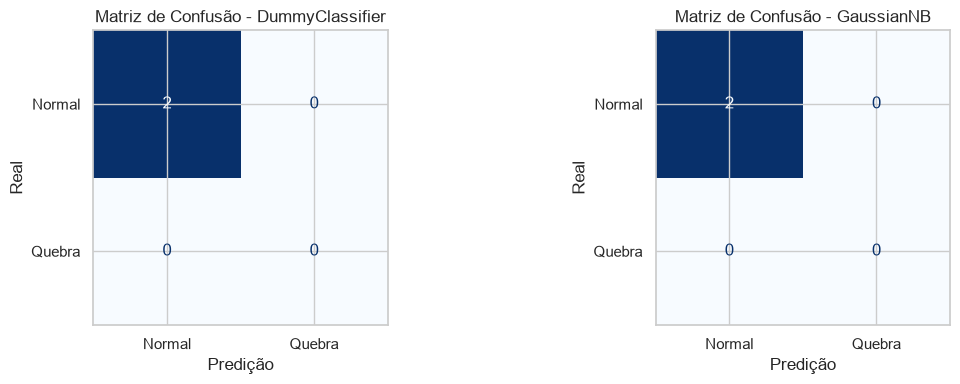

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Quebra'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Matriz de Confusão - {name}')
    ax.set_xlabel('Predição')
    ax.set_ylabel('Real')

plt.tight_layout()
plt.show()


## 5. Baseline de persistência e comparação final

Para fechar a Sprint 3, vamos incluir o baseline de persistência e comparar os três modelos no mesmo split temporal.

> Importante: como o conjunto de teste atual não contém casos positivos, a leitura mais útil continua sendo a estabilidade temporal e a ausência de evidência de eventos da classe 1 no período de teste.
>
> A tabela final abaixo consolida a comparação de acurácia e também o desempenho por classe, mostrando explicitamente que a classe `Quebra` não tem suporte estatístico neste teste.


In [18]:
persistencia_df = df.copy()
persistencia_df['predicao_persistencia'] = persistencia_df['quebra_safra'].shift(1)

persistencia_test = persistencia_df.loc[test_mask].dropna(subset=['predicao_persistencia']).copy()
y_true_persistencia = persistencia_test['quebra_safra']
y_pred_persistencia = persistencia_test['predicao_persistencia']

print('Persistência (baseline temporal):')
print(f'Teste de persistência: {len(persistencia_test)} amostras')
print(f'Classe alvo no teste de persistência: {y_true_persistencia.value_counts().to_dict()}')
print('---')

baseline_models = {
    'DummyClassifier': lambda: dummy_pipeline.predict(X_test),
    'Persistência': lambda: y_pred_persistencia,
    'GaussianNB': lambda: gaussian_pipeline.predict(X_test),
}

comparison_rows = []
per_class_rows = []

for name, pred_fn in baseline_models.items():
    y_pred = pred_fn()
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    confusion = confusion_matrix(y_test, y_pred, labels=[0, 1])

    comparison_rows.append({
        'modelo': name,
        'accuracy': accuracy,
        'precision_weighted': precision,
        'recall_weighted': recall,
        'f1_weighted': f1,
        'matriz_confusao': confusion.tolist()
    })

    for label, label_name in enumerate(['Normal', 'Quebra']):
        precision_cls, recall_cls, f1_cls, support = precision_recall_fscore_support(
            y_test,
            y_pred,
            labels=[label],
            zero_division=0
        )
        per_class_rows.append({
            'modelo': name,
            'classe': label_name,
            'precision': precision_cls[0],
            'recall': recall_cls[0],
            'f1': f1_cls[0],
            'support': support[0],
        })

comparison_df = pd.DataFrame(comparison_rows)
per_class_df = pd.DataFrame(per_class_rows)

print('Tabela comparativa agregada:')
display(comparison_df.sort_values('accuracy', ascending=False))

print('\nTabela comparativa por classe:')
display(per_class_df.sort_values(['modelo', 'classe']))

if y_test.nunique() < 2:
    print('\nConclusão da comparação:')
    print('- os três baselines ficam indistinguíveis numericamente neste teste porque ele não contém eventos da classe 1;')
    print('- qualquer métrica da classe Quebra é estatisticamente nula porque support = 0 no conjunto de teste;')
    print('- a análise correta aqui é qualitativa: o desenho do teste, a ausência de casos positivos e o custo de falsos negativos para o negócio;')
    print('- para uma leitura real de risco de quebra, o próximo passo deve ser ampliar a janela de avaliação e incluir casos positivos do evento de interesse.')


Persistência (baseline temporal):
Teste de persistência: 2 amostras
Classe alvo no teste de persistência: {0: 2}
---
Tabela comparativa agregada:


,modelo,accuracy,precision_weighted,recall_weighted,f1_weighted,matriz_confusao
0,DummyClassifier,1.0,1.0,1.0,1.0,"[[2, 0], [0, 0]]"
1,Persistência,1.0,1.0,1.0,1.0,"[[2, 0], [0, 0]]"
2,GaussianNB,1.0,1.0,1.0,1.0,"[[2, 0], [0, 0]]"



Tabela comparativa por classe:


,modelo,classe,precision,recall,f1,support
0,DummyClassifier,Normal,1.0,1.0,1.0,2
1,DummyClassifier,Quebra,0.0,0.0,0.0,0
4,GaussianNB,Normal,1.0,1.0,1.0,2
5,GaussianNB,Quebra,0.0,0.0,0.0,0
2,Persistência,Normal,1.0,1.0,1.0,2
3,Persistência,Quebra,0.0,0.0,0.0,0



Conclusão da comparação:
- os três baselines ficam indistinguíveis numericamente neste teste porque ele não contém eventos da classe 1;
- qualquer métrica da classe Quebra é estatisticamente nula porque support = 0 no conjunto de teste;
- a análise correta aqui é qualitativa: o desenho do teste, a ausência de casos positivos e o custo de falsos negativos para o negócio;
- para uma leitura real de risco de quebra, o próximo passo deve ser ampliar a janela de avaliação e incluir casos positivos do evento de interesse.


## 6. Leitura dos erros e independência condicional

- O `DummyClassifier` serve como piso de acurácia e representa a estratégia mais simples possível. Em contexto altamente desbalanceado, ele pode parecer competitivo por pura regra de maioria, mas isso não significa que o problema de risco foi aprendido.
- A persistência funciona como baseline temporal: a previsão de um ano é o valor observado no ano anterior. Nesse contexto, ela é útil para medir quanto da variação da série pode ser explicada sem modelos mais sofisticados.
- O `GaussianNB` é um baseline probabilístico e, mesmo sendo simples, ajuda a validar se a distribuição climática possui alguma sinalização útil para separar as classes.
- A leitura crítica neste sprint é que os testes atuais são muito pequenos e, sobretudo, não contêm eventos da classe positiva. Portanto, a acurácia perfeita não representa desempenho real do risco de quebra de safra; ela reflete a ausência de observações da classe 1 no período avaliado.
- A hipótese de independência condicional do Naive Bayes não é estritamente verdadeira em dados climáticos, porque variáveis como precipitação, temperatura e umidade do solo são correlacionadas entre si. Ainda assim, como baseline pedagógico, esse modelo é útil para entender a estrutura inicial dos dados antes de passar para modelos mais flexíveis.
- Do ponto de vista de negócio, o erro mais caro é o falso negativo: prever “Normal” quando a safra realmente quebra. Como o evento de interesse ainda não apareceu no conjunto de teste, os indicadores de risco ficam inconclusivos até a janela de avaliação incluir casos positivos.

> O ponto central do sprint é a metodologia e a interpretação: a cadeia de Pipeline + split temporal + baselines está correta, mas a avaliação quantitativa precisa ser lida com cautela porque a amostra de teste é insuficiente para a classe rara. O próximo passo é ampliar a janela de avaliação ou usar uma estratégia de validação temporal mais robusta antes de inferir desempenho real em negócio.
